# Практикалық жұмыс №6
## Тақырыбы: Деректерді классификациялау үшін көпқабатты тікелей таралу нейрондық желісін жүзеге асыру (Multilayer Perceptron – MLP)
**Оқу бағдарламасы:** 6B06106 – Computer Science  
**Орындаған:** [Имя удалено по соображениям конфиденциальности]  
**Тексерген:** аға оқытушы [Имя удалено по соображениям конфиденциальности]  
**Вариант:** 14 (нұсқа №4: Шарап түрлерін классификациялау / Wine classification)

### 1. Қажетті кітапханаларды импорттау және деректерді жүктеу

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Графиктердің стилі
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Деректерді жүктеу (250 бақылау)
df = pd.read_csv('data.csv')
print("Деректер өлшемі:", df.shape)
df.head()

Деректер өлшемі: (250, 21)


,sample_id,sommelier_name,sommelier_gender,sommelier_birth_year,vineyard_region,vintage_year,wine_category,alcohol,malic_acid,ash,...,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,wine_class
0,WN_2026_1001,Қасымова Аружан,Әйел,1981,Шымкент маңы,2020,Ақ десертті,13.97,1.91,2.61,...,103.8,2.76,3.61,0.34,1.71,6.20,1.00,2.99,1169.0,0
1,WN_2026_1002,Кәрімов Мұрат,Ер,1979,Түркістан облысы (Сарыағаш),2018,Ақ десертті,11.25,0.74,2.06,...,99.8,1.77,1.08,0.54,1.49,3.15,0.78,2.52,538.0,1
2,WN_2026_1003,Әубәкірова Мәдина,Әйел,1984,Жамбыл облысы (Мерке),2022,Ақ десертті,12.54,3.74,2.33,...,92.7,2.35,0.78,0.32,1.49,4.58,0.70,1.27,477.0,2
3,WN_2026_1004,Жақыпов Нұрлан,Ер,1992,Жамбыл облысы (Мерке),2024,Қызыл классикалық құрғақ,12.39,2.68,2.29,...,89.4,1.46,1.57,0.30,2.26,3.41,0.71,2.95,459.0,1
4,WN_2026_1005,Кәрімов Айдос,Ер,1995,Түркістан облысы (Сарыағаш),2018,Қызыл таңдаулы,11.91,2.55,2.57,...,80.4,2.09,2.32,0.48,1.34,2.92,0.84,2.19,648.0,1


### 2. Белгілерді талдау және кластардың таралуы

In [2]:
feature_cols = [
    'alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
    'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins',
    'color_intensity', 'hue', 'od280_od315', 'proline'
]
target_col = 'wine_class'

X = df[feature_cols]
y = df[target_col]

print("Кластардың таралуы:")
print(y.value_counts())

# Статистикалық көрсеткіштер
X.describe().round(2)

Кластардың таралуы:
wine_class
0    85
1    85
2    80
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
count,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00,250.00
mean,13.08,2.54,2.37,19.59,101.84,2.29,1.96,0.38,1.58,5.30,0.94,2.55,770.44
std,0.81,1.09,0.26,3.12,12.92,0.61,1.03,0.12,0.55,2.52,0.22,0.70,305.84
min,11.09,0.74,1.46,11.20,70.00,0.98,0.34,0.13,0.40,1.30,0.48,1.27,278.00
25%,12.43,1.62,2.23,17.50,93.32,1.84,0.98,0.29,1.20,3.55,0.74,1.92,542.00
50%,13.16,2.42,2.42,19.30,100.55,2.29,2.20,0.36,1.58,4.93,0.98,2.72,686.00
75%,13.78,3.17,2.55,21.60,109.40,2.78,2.84,0.46,2.02,6.83,1.10,3.10,972.25
max,14.69,5.80,3.02,30.00,142.70,3.51,3.80,0.63,2.94,13.00,1.60,3.94,1680.00


### 3. Белгілердің корреляциялық матрицасын құру

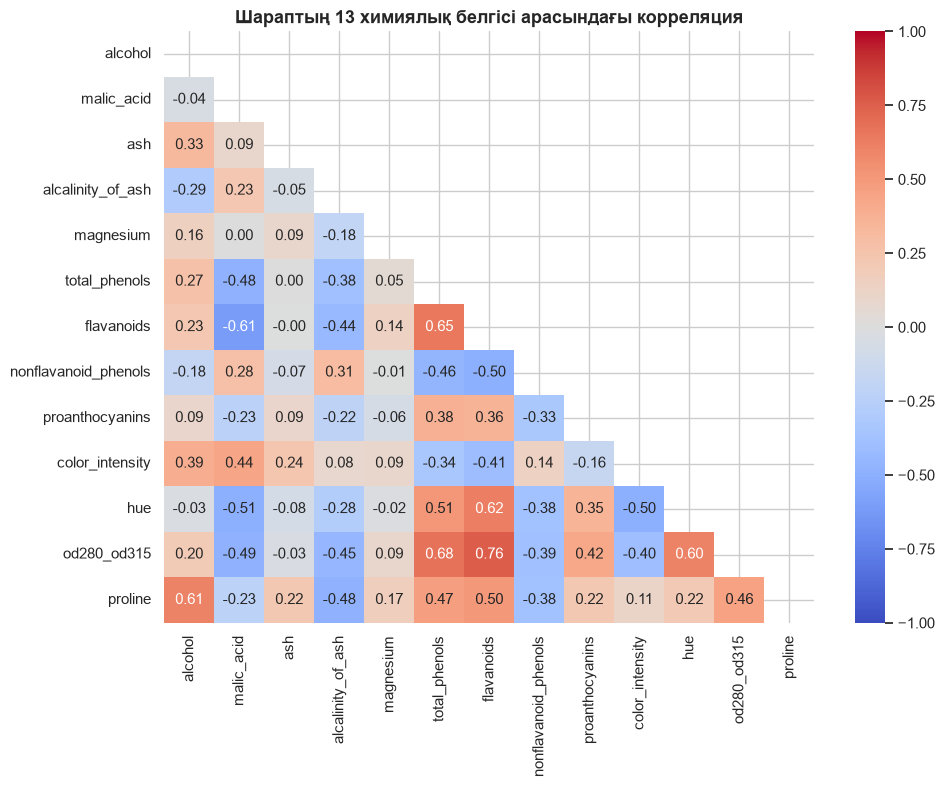

In [3]:
plt.figure(figsize=(10, 8))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Шараптың 13 химиялық белгісі арасындағы корреляция', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. Деректерді оқыту және тестілеу жиындарына бөлу және стандарттау

In [4]:
# Оқыту (80%) және тестілеу (20%) жиындарына бөлу
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# StandardScaler арқылы масштабтау
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Оқыту жиынының өлшемі: {X_train_scaled.shape}")
print(f"Тестілеу жиынының өлшемі: {X_test_scaled.shape}")

Оқыту жиынының өлшемі: (200, 13)
Тестілеу жиынының өлшемі: (50, 13)


### 5. 4-нұсқа бойынша (32, 16) архитектуралы MLP моделін құру және оқыту

In [5]:
# MLPClassifier моделі: 2 жасырын қабат (32 және 16 нейрон), ReLU, Adam
mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=600,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)
print(f"Модель оқытылды. Орындалған эпохалар саны: {len(mlp.loss_curve_)}")
print(f"Ақырғы қателік мәні (Loss): {mlp.loss_curve_[-1]:.6f}")

Модель оқытылды. Орындалған эпохалар саны: 258
Ақырғы қателік мәні (Loss): 0.009458


### 6. Оқыту динамикасы: Loss функциясының графигі

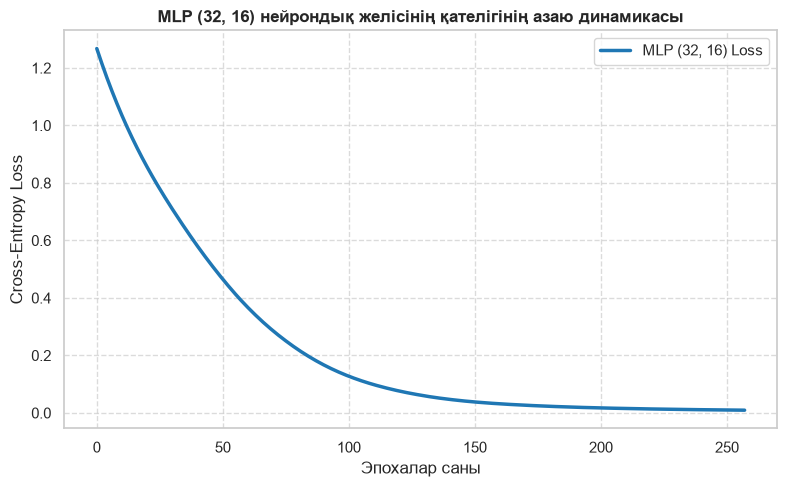

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, color='#1f77b4', linewidth=2.5, label='MLP (32, 16) Loss')
plt.title('MLP (32, 16) нейрондық желісінің қателігінің азаю динамикасы', fontsize=12, fontweight='bold')
plt.xlabel('Эпохалар саны')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

### 7. Модельдің сапасын тестілеу және метрикаларды есептеу

In [7]:
y_pred = mlp.predict(X_test_scaled)

print("=== КЛАССИФИКАЦИЯ НӘТИЖЕЛЕРІ ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, average='weighted'):.4f}")

print("\nТолық Classification Report:")
print(classification_report(y_test, y_pred, target_names=['0-сынып', '1-сынып', '2-сынып']))

=== КЛАССИФИКАЦИЯ НӘТИЖЕЛЕРІ ===
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Толық Classification Report:
              precision    recall  f1-score   support

     0-сынып       1.00      1.00      1.00        17
     1-сынып       1.00      1.00      1.00        17
     2-сынып       1.00      1.00      1.00        16

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



### 8. Қателіктер матрицасы (Confusion Matrix)

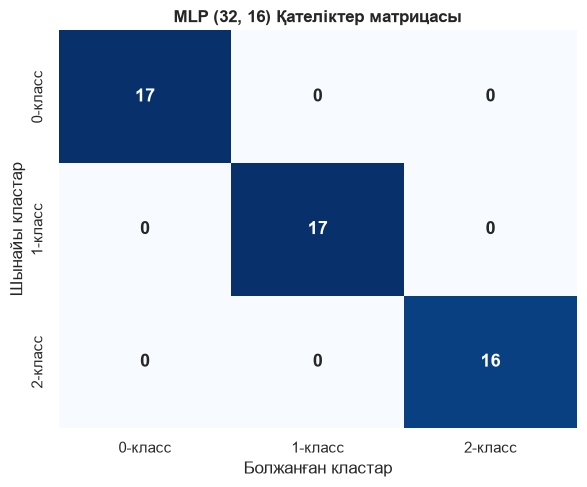

In [8]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['0-класс', '1-класс', '2-класс'],
            yticklabels=['0-класс', '1-класс', '2-класс'], annot_kws={"size": 13, "weight": "bold"})
plt.title('MLP (32, 16) Қателіктер матрицасы', fontsize=12, fontweight='bold')
plt.xlabel('Болжанған кластар')
plt.ylabel('Шынайы кластар')
plt.tight_layout()
plt.show()

### 9. Әртүрлі архитектураларды салыстыру

In [9]:
arch_list = {
    'MLP (16)': (16,),
    'MLP (32, 16)': (32, 16),
    'MLP (64, 32)': (64, 32),
    'MLP (64, 32, 16)': (64, 32, 16)
}

res = []
for name, arch in arch_list.items():
    clf = MLPClassifier(hidden_layer_sizes=arch, activation='relu', solver='adam', max_iter=600, random_state=42)
    clf.fit(X_train_scaled, y_train)
    p = clf.predict(X_test_scaled)
    res.append({
        'Архитектура': name,
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, average='weighted'),
        'Recall': recall_score(y_test, p, average='weighted'),
        'F1-score': f1_score(y_test, p, average='weighted'),
        'Эпохалар': len(clf.loss_curve_),
        'Loss': clf.loss_curve_[-1]
    })

df_res = pd.DataFrame(res)
df_res

,Архитектура,Accuracy,Precision,Recall,F1-score,Эпохалар,Loss
0,MLP (16),1.0,1.0,1.0,1.0,434,0.021424
1,"MLP (32, 16)",1.0,1.0,1.0,1.0,258,0.009458
2,"MLP (64, 32)",1.0,1.0,1.0,1.0,166,0.005825
3,"MLP (64, 32, 16)",1.0,1.0,1.0,1.0,146,0.004491


### 10. Жаңа шарап үлгісінің класын және ықтималдығын болжау

In [10]:
# Жаңа шарап сынамасының көрсеткіштері
sample = np.array([[13.5, 2.1, 2.4, 18.0, 105.0, 2.7, 2.8, 0.3, 1.8, 5.2, 1.05, 3.1, 1050.0]])
sample_scaled = scaler.transform(sample)

pred_c = mlp.predict(sample_scaled)[0]
probs = mlp.predict_proba(sample_scaled)[0]

print(f"Жаңа сынама бойынша болжанған класс: {pred_c}-сынып")
for i, pr in enumerate(probs):
    print(f"  {i}-сыныпқа тиесілі болу ықтималдығы: {pr*100:.2f}%")

Жаңа сынама бойынша болжанған класс: 0-сынып
  0-сыныпқа тиесілі болу ықтималдығы: 98.96%
  1-сыныпқа тиесілі болу ықтималдығы: 0.23%
  2-сыныпқа тиесілі болу ықтималдығы: 0.80%


C:\Users\McFucker\Desktop\алгоритмы\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
